# Linear regression from the Gram matrix

For a Gaussian linear model $y = X\beta + \varepsilon$, $\varepsilon \sim \mathcal N(0, \sigma^2 I)$, expand
the residual sum of squares:

$$\lVert y - X\beta\rVert^2 = y^\top y - 2\beta^\top X^\top y + \beta^\top X^\top X\beta .$$

So $T = (n,\; X^\top X,\; X^\top y,\; y^\top y)$ is sufficient for $(\beta, \sigma)$. With $p$ predictors
that is $p(p+1)/2 + p + 2$ numbers, independent of $n$. The log-likelihood is

$$\ell(\beta,\sigma) = -\tfrac n2 \log(2\pi\sigma^2) - \frac{y^\top y - 2\beta^\top X^\top y + \beta^\top X^\top X \beta}{2\sigma^2}.$$

Two practical consequences: the per-gradient cost no longer scales with $n$, and the summaries
are *additive*, so they can be computed in SQL, in chunks, or across machines and simply summed.

In [1]:
import time
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(505)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)


def timed_fit(model, label, n_rows, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    return idata, {"model": label, "rows in likelihood": n_rows, "wall time (s)": round(secs, 1),
                   "min ESS/s": round(ess / secs, 1)}

## A million rows, ten predictors (with continuous covariates)

Unlike the count models, nothing here needs categorical covariates. Continuous predictors are fine
because sufficiency comes from the Gaussian's quadratic form, not from grouping identical rows.

In [2]:
n, p = 1_000_000, 10
X = np.column_stack([np.ones(n), rng.normal(size=(n, p - 1))])
X[:, 2] = 0.6 * X[:, 1] + 0.8 * X[:, 2]                       # some collinearity
beta_true = rng.normal(0, 0.5, p)
sigma_true = 2.0
y = X @ beta_true + rng.normal(0, sigma_true, n)

The summaries, computed in ten chunks to make the streaming point: each chunk could live in a
different file or partition, and we never hold more than one at a time.

In [3]:
XtX, Xty, yty = np.zeros((p, p)), np.zeros(p), 0.0
for Xc, yc in zip(np.array_split(X, 10), np.array_split(y, 10)):
    XtX += Xc.T @ Xc
    Xty += Xc.T @ yc
    yty += yc @ yc
print(f"{n:,} x {p} design -> {XtX.size + Xty.size + 2} numbers")

1,000,000 x 10 design -> 112 numbers


In [4]:
coords = {"coef": [f"b{j}" for j in range(p)]}

with pm.Model(coords=coords) as lm_full:
    beta = pm.Normal("beta", 0, 2, dims="coef")
    sigma = pm.HalfNormal("sigma", 5)
    pm.Normal("y", X @ beta, sigma, observed=y)

with pm.Model(coords=coords) as lm_suff:
    beta = pm.Normal("beta", 0, 2, dims="coef")
    sigma = pm.HalfNormal("sigma", 5)
    rss = yty - 2 * beta @ Xty + beta @ XtX @ beta
    pm.Potential("loglik", -0.5 * n * pm.math.log(2 * np.pi * sigma**2) - rss / (2 * sigma**2))

idata_full, rec_full = timed_fit(lm_full, "Normal, 1M raw rows", n)
idata_suff, rec_suff = timed_fit(lm_suff, "Potential on (n, X'X, X'y, y'y)", 1)

NUTS[nutpie]: [beta, sigma]
NUTS[nutpie]: [beta, sigma]


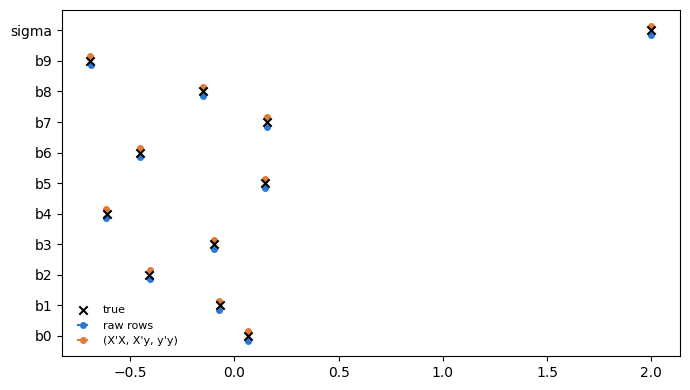

In [5]:
#| label: fig-lm-equiv
#| fig-cap: "Posterior means and 89% intervals for all ten coefficients and σ, raw rows vs Gram-matrix summaries (offset vertically for visibility). True values marked with ×."
summ = {k: az.summary(v, var_names=["beta", "sigma"]) for k, v in [("raw rows", idata_full), ("(X'X, X'y, y'y)", idata_suff)]}
truth = np.append(beta_true, sigma_true)
fig, ax = plt.subplots(figsize=(7, 4))
ypos = np.arange(p + 1)
for off, (k, s), col in zip([-0.15, 0.15], summ.items(), ["#2a78d6", "#e07b39"]):
    lo, hi = s.filter(like="_lb").iloc[:, 0], s.filter(like="_ub").iloc[:, 0]
    ax.errorbar(s["mean"], ypos + off, xerr=[s["mean"] - lo, hi - s["mean"]], fmt="o", ms=4, color=col, label=k)
ax.scatter(truth, ypos, marker="x", color="k", zorder=3, label="true")
ax.set_yticks(ypos, list(coords["coef"]) + ["sigma"])
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
#| label: tbl-lm-speed
#| tbl-cap: "One million rows vs 112 numbers (67 distinct, since X'X is symmetric)."
speed = pd.DataFrame([rec_full, rec_suff])
speed["max |Δ posterior mean|"] = ["", float(np.abs(summ["raw rows"]["mean"].values - summ["(X'X, X'y, y'y)"]["mean"].values).max())]
speed

,model,rows in likelihood,wall time (s),min ESS/s,max |Δ posterior mean|
0,"Normal, 1M raw rows",1000000,188.8,22.5,
1,"Potential on (n, X'X, X'y, y'y)",1,2.5,1644.7,0.000081


## Extensions and limits

- **Grouped / hierarchical regressions.** Keep one $(n_g, X_g^\top X_g, X_g^\top y_g, y_g^\top y_g)$ per
  group; varying intercepts and slopes become a sum of per-group quadratic forms. Cost scales with
  the number of groups, not rows.
- **Weighted and heteroskedastic-by-group variance** work the same way with $X^\top W X$.
- **Robust likelihoods break it.** A Student-$t$ error has no fixed-dimension sufficient statistic
  (Pitman–Koopman–Darmois: outside the exponential family, sufficiency does not compress). Then you are
  in the territory of the last notebook: approximate summaries.
- **Diagnostics.** As with any `pm.Potential`, there is no pointwise log-likelihood or posterior
  predictive. Residual checks have to be computed back on the raw data, chunk by chunk.